# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

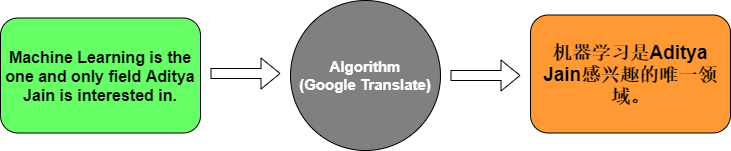

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
#!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.1429 - loss: 2.4835

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - accuracy: 0.1429 - loss: 2.4835 - val_accuracy: 0.0000e+00 - val_loss: 2.4867


Epoch 2/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.5714 - loss: 2.4752

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - accuracy: 0.5714 - loss: 2.4752 - val_accuracy: 0.0000e+00 - val_loss: 2.4889


... (143 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 1.0000 - loss: 0.4895 - val_accuracy: 0.0000e+00 - val_loss: 6.0591


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 713ms/step - accuracy: 0.5714 - loss: 1.9718

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 738ms/step - accuracy: 0.5714 - loss: 1.9718


Test Accuracy: 0.5714285969734192


In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 387ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 414ms/step


Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


**Answers:**

1. **Embedding layer:** It turns each word index (an integer such as `2` for "how") into a dense vector of 64 numbers (`output_dim=64`). The integer is just a row number in a table of learned vectors. During training these vectors are adjusted, so words used in similar ways end up with similar vectors.

3. **Encoder LSTM:** It reads the English sentence one word vector at a time and keeps a memory (hidden state) of what it has read so far. Because `return_sequences` is not set, it returns only its final hidden state: one 64-number vector that summarizes the whole English sentence. `RepeatVector` then copies this summary once for each position in the French sentence.

5. **Decoder LSTM:** It takes the repeated sentence summary and produces the output sentence one step at a time. With `return_sequences=True` it returns a hidden state for **every** time step (one per French word position), and each of these is turned into a French word by the final layer.

8. **Why softmax:** At each time step the `Dense` layer gives one score for every word in the French vocabulary. `softmax` turns these scores into probabilities between 0 and 1 that add up to 1. We can then pick the most likely word with `argmax`, and the `sparse_categorical_crossentropy` loss can compare the predicted probabilities with the correct French word index.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

#### Step 1: Load the dataset

The dataset has about 175,000 English-French sentence pairs. To keep training fast on a CPU, we keep only short sentences (up to 4 English words and 5 French words) and take a random sample of 15,000 pairs.

In [8]:
import os
import pandas as pd
import kagglehub

tf.random.set_seed(42)

path = kagglehub.dataset_download("devicharith/language-translation-englishfrench")
df = pd.read_csv(os.path.join(path, "eng_-french.csv"))
df.columns = ["english", "french"]
print("Number of sentence pairs:", len(df))

# Lowercase
df["english"] = df["english"].str.lower()
df["french"] = df["french"].str.lower()

# Keep short sentences only
df = df[(df["english"].str.split().str.len() <= 4) & (df["french"].str.split().str.len() <= 5)]
df = df.sample(15000, random_state=42)
print("Pairs used:", len(df))
df.head()

C:\Users\alibi\Documents\GitHub\NLP_Labs\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Number of sentence pairs: 175621


Pairs used: 15000


,english,french
47096,he's addicted to drugs.,il est accroché aux médicaments.
6381,stop dreaming.,arrêtez de rêver.
42773,it was not conclusive.,ce ne fut pas concluant.
4386,they're cold.,ils sont froids.
9604,who's speaking?,qui est à l'appareil ?


#### Step 2: Tokenize and pad

Same steps as above: one `Tokenizer` per language, then `pad_sequences` so all sentences have the same length. We pad at the end (`padding="post"`) so every sentence starts at the first time step.

In [9]:
tokenizer_eng2 = Tokenizer()
tokenizer_eng2.fit_on_texts(df["english"])
eng_padded2 = pad_sequences(tokenizer_eng2.texts_to_sequences(df["english"]), padding="post")

tokenizer_frn2 = Tokenizer()
tokenizer_frn2.fit_on_texts(df["french"])
frn_padded2 = pad_sequences(tokenizer_frn2.texts_to_sequences(df["french"]), padding="post")

print("English vocabulary size:", len(tokenizer_eng2.word_index))
print("French vocabulary size:", len(tokenizer_frn2.word_index))
print("English padded shape:", eng_padded2.shape)
print("French padded shape:", frn_padded2.shape)

English vocabulary size: 4476
French vocabulary size: 7603
English padded shape: (15000, 7)
French padded shape: (15000, 8)


#### Step 3: Build and train the model

Same encoder-decoder LSTM as above (Embedding → LSTM → RepeatVector → LSTM → TimeDistributed Dense). Because the vocabulary is much larger, we use bigger layers (128-dimensional embeddings, 256 LSTM units) and a batch size of 64.

In [10]:
eng_train2, eng_test2, frn_train2, frn_test2 = train_test_split(eng_padded2, frn_padded2, test_size=0.2, random_state=42)

model2 = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(tokenizer_eng2.word_index) + 1, output_dim=128),
    tf.keras.layers.LSTM(256),
    tf.keras.layers.RepeatVector(frn_padded2.shape[1]),
    tf.keras.layers.LSTM(256, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(tokenizer_frn2.word_index) + 1, activation='softmax'))
])

model2.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

model2.fit(eng_train2, np.expand_dims(frn_train2, -1), epochs=30, batch_size=64, validation_split=0.1, verbose=2)

loss, accuracy = model2.evaluate(eng_test2, np.expand_dims(frn_test2, -1), verbose=0)
print(f'Test Accuracy: {accuracy}')

Epoch 1/30


169/169 - 19s - 115ms/step - accuracy: 0.5205 - loss: 4.1248 - val_accuracy: 0.5369 - val_loss: 3.5765


Epoch 2/30


169/169 - 15s - 87ms/step - accuracy: 0.5392 - loss: 3.4098 - val_accuracy: 0.5427 - val_loss: 3.4867


Epoch 3/30


169/169 - 14s - 86ms/step - accuracy: 0.5423 - loss: 3.3091 - val_accuracy: 0.5427 - val_loss: 3.4497


... (51 outputs left out)

169/169 - 14s - 85ms/step - accuracy: 0.6993 - loss: 1.3999 - val_accuracy: 0.6508 - val_loss: 2.6049


Epoch 30/30


169/169 - 14s - 85ms/step - accuracy: 0.7073 - loss: 1.3330 - val_accuracy: 0.6536 - val_loss: 2.6069


Test Accuracy: 0.6551250219345093


#### Step 4: Translate

We translate some test sentences (the model never saw them during training) and compare with the correct French translation.

In [11]:
def translate(sentence):
    sequence = tokenizer_eng2.texts_to_sequences([sentence.lower()])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded2.shape[1], padding="post")
    predicted_sequence = model2.predict(padded_sequence, verbose=0)
    translated_sequence = np.argmax(predicted_sequence, axis=-1)
    return tokenizer_frn2.sequences_to_texts(translated_sequence)[0]

test_english = tokenizer_eng2.sequences_to_texts(eng_test2[:15])
test_french = tokenizer_frn2.sequences_to_texts(frn_test2[:15])

for eng, frn in zip(test_english, test_french):
    print(f"English:   {eng}")
    print(f"Correct:   {frn}")
    print(f"Predicted: {translate(eng)}")
    print()

English:   tom died last year
Correct:   tom est mort l'année dernière


Predicted: tom a l'air très

English:   he's a notorious liar
Correct:   c'est un menteur notoire
Predicted: il est trop

English:   you can't help me
Correct:   vous ne pouvez pas m'aider


Predicted: vous ne pouvez pas pas

English:   stay away
Correct:   reste à l'écart
Predicted: restez

English:   are you following me
Correct:   vous me suivez


Predicted: vous tu vous ici

English:   we grew up together
Correct:   nous grandîmes ensemble
Predicted: nous sommes complètement ensemble

English:   turn right there
Correct:   tournez là à droite


Predicted: venez le

English:   i resent that
Correct:   ça me déplaît
Predicted: je veux le

English:   i have an excuse
Correct:   j'ai une excuse


Predicted: j'adore cette appartement

English:   the boy remained silent
Correct:   le garçon est resté silencieux
Predicted: la situation a empiré

English:   didn't you know that
Correct:   t’étais pas au courant


Predicted: ne vous pas pas pas

English:   i'm dreading the exam
Correct:   je crains l'examen
Predicted: je capte

English:   it's ironic
Correct:   c'est ironique


Predicted: c'est important

English:   you're wasting my time
Correct:   vous gaspillez mon temps
Predicted: tu es un mon

English:   i already feel relaxed
Correct:   je me sens déjà détendu


Predicted: je me sens trahie



In [12]:
# Short product / shopping sentences, as in the use case
for sentence in ["I like it.", "It is very good.", "This is expensive.", "Thank you.", "I want to buy this."]:
    print(f"{sentence} -> {translate(sentence)}")

I like it. -> j'aime


It is very good. -> c'était très très


This is expensive. -> c'est


Thank you. -> tenez toi


I want to buy this. -> je veux de la


**Results:**

- The model reaches about **65% test accuracy** (training accuracy about 71%). This accuracy is per word position and includes the padding zeros, so it overstates translation quality.
- **What works:** The model learned common sentence starts and short phrases. It translates "you can't help me" → "vous ne pouvez pas ...", "i already feel relaxed" → "je me sens ...", "it's ..." → "c'est ...", "I like it." → "j'aime", and "we grew up together" → "nous ... ensemble". The grammar of the first words (subject + verb form) is usually right.
- **What does not work:** Rare words are often replaced with frequent ones ("ironique" → "important", "excuse" → "appartement"), words are repeated ("pas pas pas", "très très"), and longer sentences lose their meaning ("the boy remained silent" → "la situation a empiré").
- **Why:** The encoder squeezes the whole English sentence into one 256-number vector, and the decoder has to rebuild every French word from it. With only 15,000 short pairs and many words seen just once or twice, the model cannot learn most of the vocabulary. The validation loss stops improving while the training loss keeps dropping, so the model is starting to overfit.

**For the e-commerce company:** This simple model is good for learning how machine translation works, but its output is not good enough for real product listings or customer reviews. Better results would need (1) much more training data (the full 175k pairs and real product text), (2) a GPU and longer training, and (3) a stronger architecture, such as an **attention** mechanism (Lab 11) so the decoder can look at every English word instead of a single summary vector, or a pre-trained model like the ones used in Lab 7.